# 1. Quickstart: forecasting flu in Boston's neighborhoods

This notebook runs the whole workflow on the Boston data that ships with the package:

1. **Look at the data.**
2. **Backtest.** Would these models have worked on a past season? Each one is compared with *persistence*, the forecast "next week looks like this week".
3. **Forecast** the weeks after the last observation, with uncertainty bands and a trust check.
4. **Save** the results, including in the CDC FluSight format.

Install first with `pip install "areaFluForecast[plot]"`.

> **Speed.** To keep this notebook to about half an hour on a laptop, every learned model below uses a 2-member ensemble (`n_seeds=2`) instead of the default 10. Small ensembles are noisier, so treat the numbers here as a demonstration. For real use, drop the `configs=SMALL` argument.

> **What to expect.** Small, untuned ensembles understate the models. In the paper's evaluation, with equal tuning and 10 members, the graph model's WIS was 18-28% below persistence in Boston. Every model, tuned or not, runs about as far behind the curve as persistence does: its advantage is the size of the curve, not earlier turns. The backtest report's timing section shows this.

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import areafluforecast as af

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

## The data

These are weekly emergency-department influenza-like-illness rates per 100,000 residents for 14 Boston neighborhoods, from the Boston Public Health Commission's public dashboard, together with which neighborhoods border each other and weekly weather. `summary()` is the first thing to check with your own data, too.

In [2]:
city = af.load_sample("boston")
print(city.summary())

Boston: 14 areas, 436 weeks (2017-12-31 to 2026-05-03), flu season Oct-Mar
  graph: 23 borders between areas, 7 anchors with 21 borders
  missing area-weeks: 7.0%
  weather: yes | static characteristics: none
  complete seasons available to backtest: 2020-21, 2021-22, 2022-23, 2023-24, 2024-25


In [3]:
city.rates.tail()

,Allston/Brighton,Back Bay/Beacon Hill/Downtown/North End/West End,Charlestown,Dorchester,East Boston,Fenway,Hyde Park,Jamaica Plain,Mattapan,Roslindale,Roxbury,South Boston,South End,West Roxbury
week,,,,,,,,,,,,,,
2026-04-05,17.0,8.6,15.5,50.85,6.2,9.2,11.5,5.1,17.0,30.5,58.8,4.2,15.3,7.3
2026-04-12,11.3,10.3,20.6,45.10,14.0,1.3,13.8,10.2,11.3,NaN,32.7,12.7,28.0,14.7
2026-04-19,15.6,3.4,NaN,28.20,6.2,2.6,11.5,10.2,5.7,17.5,26.1,6.3,22.9,3.7
2026-04-26,7.1,10.3,5.2,25.45,9.4,4.0,13.8,8.5,11.3,21.8,32.7,NaN,7.6,11.0
2026-05-03,4.2,10.3,20.6,30.65,6.2,1.3,13.8,5.1,11.3,30.5,22.9,4.2,10.2,NaN


Blank cells are weeks BPHC suppressed because the count was small. The models skip them when scoring and never treat them as zero.

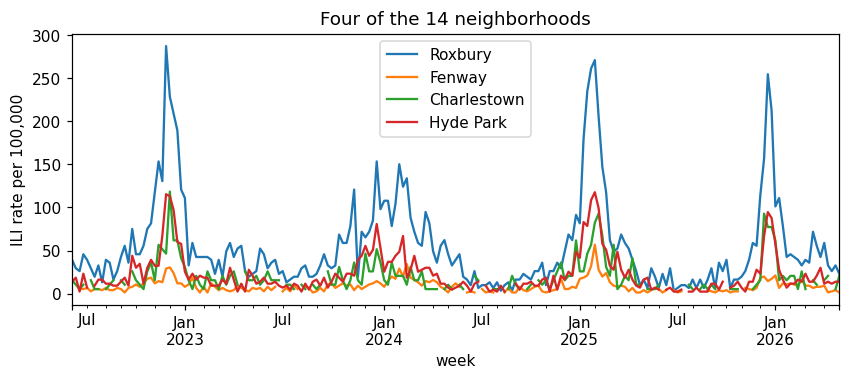

In [4]:
ax = city.rates.loc["2022-06":, ["Roxbury", "Fenway", "Charlestown", "Hyde Park"]].plot(figsize=(9, 3.2))
ax.set_ylabel("ILI rate per 100,000"); ax.set_title("Four of the 14 neighborhoods");

## Step 1: would it have worked here? (backtest)

`backtest` trains every model on the weeks *before* a past season, forecasts every week of that season, and scores the forecasts. `seasons=1` uses the most recent complete season, which for this data runs June 2024 to May 2025.

In [5]:
SMALL = {"gnn_st": {"n_seeds": 2}, "lstm": {"n_seeds": 2}, "colagnn": {"n_seeds": 2}}

bt = af.backtest(city, seasons=1, horizons=(1, 2), configs=SMALL, out_dir="runs")

Budget: 16 epochs x 1 seeds


--- seed 1 (1/1) ---


Boston: 14 areas, 436 weeks (2017-12-31 to 2026-05-03), flu season Oct-Mar
  graph: 23 borders between areas, 7 anchors with 21 borders
  missing area-weeks: 7.0%
  weather: yes | static characteristics: none
  complete seasons available to backtest: 2020-21, 2021-22, 2022-23, 2023-24, 2024-25


Epoch 1 |   6.2% | 2024-25 1wk gnn_st seed 42 | elapsed 5m20s | left ~1h20m


Epoch 2 |  12.5% | 2024-25 1wk gnn_st seed 43 | elapsed 10m30s | left ~1h13m


...

Epoch 14 |  87.5% | 2024-25 2wk colagnn seed 43 | elapsed 20m47s | left ~2m58s


Epoch 15 |  93.8% | 2024-25 2wk persistence | elapsed 20m47s | left ~1m23s


Epoch 16 | 100.0% | 2024-25 2wk seasonal_naive | elapsed 20m47s | left ~0m00s


Outputs: runs/boston/backtest_20261004-234917


# Backtest: boston

Seasons: 2024-25. Every number is from weeks the models never trained on.

**Relative WIS** is the model's weighted interval score divided by persistence's on the same weeks: below 1 means it beat "next week looks like this week". **p (Holm)** asks whether the weekly gap is bigger than week-to-week noise, adjusted for the number of comparisons.

| weeks ahead | model | WIS | relative WIS | p (Holm) | verdict |
|---|---|---|---|---|---|
| 1 | colagnn | 4.89 | 0.77 | 0.001 | better than persistence |
| 1 | gnn_st | 4.97 | 0.78 | 0.000 | better than persistence |
| 1 | lstm | 5.19 | 0.81 | 0.047 | better than persistence |
| 1 | seasonal_naive | 10.64 | 1.66 | 0.002 | worse than persistence |
| 2 | gnn_st | 6.07 | 0.68 | 0.055 | not clearly better than persistence |
| 2 | lstm | 7.55 | 0.84 | 0.742 | not clearly better than persistence |
| 2 | colagnn | 8.52 | 0.95 | 0.768 | not clearly better than persistence |
| 2 | seasonal_naive | 10.64 | 1.19 | 0.742 | no better t

### Reading the report

- **WIS** (weighted interval score) asks how good the whole forecast was, the uncertainty band as well as the single number. Lower is better, and it's in rate units. CDC FluSight ranks forecasts by it.
- **Relative WIS** is the model's WIS divided by persistence's, on the same weeks. Below 1 means the model beat "next week looks like this week".
- **p (Holm)** asks whether the gap could just be week-to-week noise. Below 0.05 means it is unlikely to be.

In [6]:
display(Markdown(bt.report(show=False)))

# Backtest: boston

Seasons: 2024-25. Every number is from weeks the models never trained on.

**Relative WIS** is the model's weighted interval score divided by persistence's on the same weeks: below 1 means it beat "next week looks like this week". **p (Holm)** asks whether the weekly gap is bigger than week-to-week noise, adjusted for the number of comparisons.

| weeks ahead | model | WIS | relative WIS | p (Holm) | verdict |
|---|---|---|---|---|---|
| 1 | colagnn | 4.89 | 0.77 | 0.001 | better than persistence |
| 1 | gnn_st | 4.97 | 0.78 | 0.000 | better than persistence |
| 1 | lstm | 5.19 | 0.81 | 0.047 | better than persistence |
| 1 | seasonal_naive | 10.64 | 1.66 | 0.002 | worse than persistence |
| 2 | gnn_st | 6.07 | 0.68 | 0.055 | not clearly better than persistence |
| 2 | lstm | 7.55 | 0.84 | 0.742 | not clearly better than persistence |
| 2 | colagnn | 8.52 | 0.95 | 0.768 | not clearly better than persistence |
| 2 | seasonal_naive | 10.64 | 1.19 | 0.742 | no better than persistence |

Coverage of the 95% band (should be near 95%):

- colagnn, 1 wk: 93.6%
- gnn_st, 1 wk: 93.1%
- lstm, 1 wk: 94.1%
- persistence, 1 wk: 93.1%
- seasonal_naive, 1 wk: 97.0%
- colagnn, 2 wk: 86.0%
- gnn_st, 2 wk: 90.7%
- lstm, 2 wk: 88.8%
- persistence, 2 wk: 89.1%
- seasonal_naive, 2 wk: 97.0%

## Step 2: forecast the next weeks

`forecast` trains on every week whose outcome is already known, then forecasts from the last observed week. It also reads the backtest above and marks each model and horizon with how it did there. We ask for 3 weeks ahead even though the backtest only covered 1 and 2, to show what the trust check says about a horizon nobody tested.

In [7]:
fc = af.forecast(city, horizons=(1, 2, 3), configs=SMALL, out_dir="runs")

Budget: 18 epochs x 1 seeds


--- seed 1 (1/1) ---


Epoch 1 |   5.6% | 1wk gnn_st seed 42 | elapsed 5m58s | left ~1h41m


Epoch 2 |  11.1% | 1wk gnn_st seed 43 | elapsed 11m57s | left ~1h35m


Epoch 3 |  16.7% | 1wk lstm seed 42 | elapsed 11m58s | left ~59m54s


...

Epoch 15 |  83.3% | 3wk lstm seed 42 | elapsed 36m24s | left ~7m16s


Epoch 16 |  88.9% | 3wk lstm seed 43 | elapsed 36m24s | left ~4m33s


Epoch 17 |  94.4% | 3wk colagnn seed 42 | elapsed 36m32s | left ~2m08s


Epoch 18 | 100.0% | 3wk colagnn seed 43 | elapsed 36m43s | left ~0m00s


Outputs: runs/boston/forecast_20261004-234917


In [8]:
fc.summary().query("model == 'gnn_st'").head(14)

,model,horizon,target_date,area,predicted,lower,upper,trust
0,gnn_st,1,2026-05-10,Allston/Brighton,6.683712,0.000000,16.168272,better than persistence
1,gnn_st,1,2026-05-10,Back Bay/Beacon Hill/Downtown/North End/West End,6.417790,0.000000,15.678995,better than persistence
2,gnn_st,1,2026-05-10,Charlestown,12.423540,0.000000,25.372609,better than persistence
3,gnn_st,1,2026-05-10,Dorchester,30.115425,9.907169,50.323681,better than persistence
4,gnn_st,1,2026-05-10,East Boston,6.367711,0.000000,15.564412,better than persistence
5,gnn_st,1,2026-05-10,Fenway,3.732710,0.000000,10.779090,better than persistence
6,gnn_st,1,2026-05-10,Hyde Park,11.038364,0.000000,23.232664,better than persistence
7,gnn_st,1,2026-05-10,Jamaica Plain,6.532676,0.000000,15.842965,better than persistence
8,gnn_st,1,2026-05-10,Mattapan,12.385229,0.000000,25.381903,better than persistence
9,gnn_st,1,2026-05-10,Roslindale,17.851046,2.163179,33.538912,better than persistence


In [9]:
fc.trust

,model,horizon,trust
0,gnn_st,1,better than persistence
1,gnn_st,2,not clearly better than persistence
2,gnn_st,3,not backtested
3,lstm,1,better than persistence
4,lstm,2,not clearly better than persistence
5,lstm,3,not backtested
6,colagnn,1,better than persistence
7,colagnn,2,not clearly better than persistence
8,colagnn,3,not backtested


Each forecast row also carries 23 quantiles (`q0.010` ... `q0.990`), the full predictive distribution that FluSight scores.

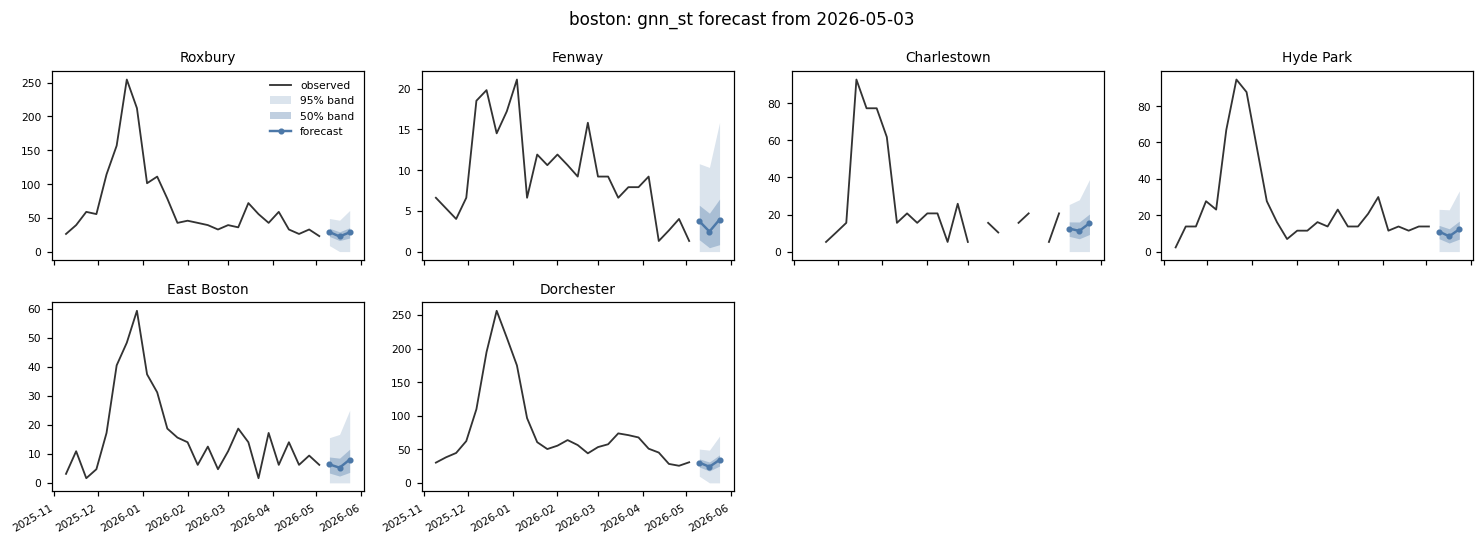

In [10]:
fig = fc.plot("gnn_st", areas=["Roxbury", "Fenway", "Charlestown", "Hyde Park",
                            "East Boston", "Dorchester"])

## Step 3: save and share

In [11]:
fc.to_csv("runs/boston_forecast.csv")
flusight = fc.to_flusight("gnn_st")
flusight.head()

,model,reference_date,target,horizon,target_end_date,location,output_type,output_type_id,value
0,gnn_st,2026-05-03,wk inc flu rate,1,2026-05-10,Allston/Brighton,quantile,0.010,0.00000
1,gnn_st,2026-05-03,wk inc flu rate,1,2026-05-10,Allston/Brighton,quantile,0.025,0.00000
2,gnn_st,2026-05-03,wk inc flu rate,1,2026-05-10,Allston/Brighton,quantile,0.050,0.00000
3,gnn_st,2026-05-03,wk inc flu rate,1,2026-05-10,Allston/Brighton,quantile,0.100,1.44173
4,gnn_st,2026-05-03,wk inc flu rate,1,2026-05-10,Allston/Brighton,quantile,0.150,2.34674


In [12]:
print("Everything this run wrote:", fc.path)
sorted(p.name for p in fc.path.iterdir())

Everything this run wrote: runs/boston/forecast_20261004-234917


['forecast.csv', 'forecast_flusight.csv', 'trust.md']

## Next

- **`02_your_own_data.ipynb`**: the file formats, building the map from a boundary file, and the errors you might hit.
- **`03_short_history_transfer.ipynb`**: what to do with only two years of data.
- **`04_reading_the_results.ipynb`**: a closer look at the backtest, and how to choose which model's forecast to use.